1.Check the Lib

In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Device: cpu


In [2]:
from google.colab import files
uploaded = files.upload()

Saving EuroSAT_RGB.zip to EuroSAT_RGB.zip


In [3]:
import os
import zipfile

zip_path = "/content/EuroSAT_RGB.zip"
extract_path = "/content/EuroSAT_RGB"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path)[:10])

Extraction completed!
['EuroSAT_RGB']


2.Load EuroSAT RGB

In [4]:
import os
from torchvision import datasets, transforms

data_path = "/content/EuroSAT_RGB/EuroSAT_RGB"

print("Folder exists:", os.path.exists(data_path))
print("Contents:", os.listdir(data_path)[:15])

Folder exists: True
Contents: ['PermanentCrop', 'HerbaceousVegetation', 'Industrial', 'AnnualCrop', 'Residential', 'SeaLake', 'River', 'Highway', 'Pasture', 'Forest']


In [5]:
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root=data_path,
    transform=transform
)

class_names = dataset.classes
num_classes = len(class_names)

print("Total images:", len(dataset))
print("Number of classes:", num_classes)
print("Classes:", class_names)

Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


Display Sample

Dataset size: 27000
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


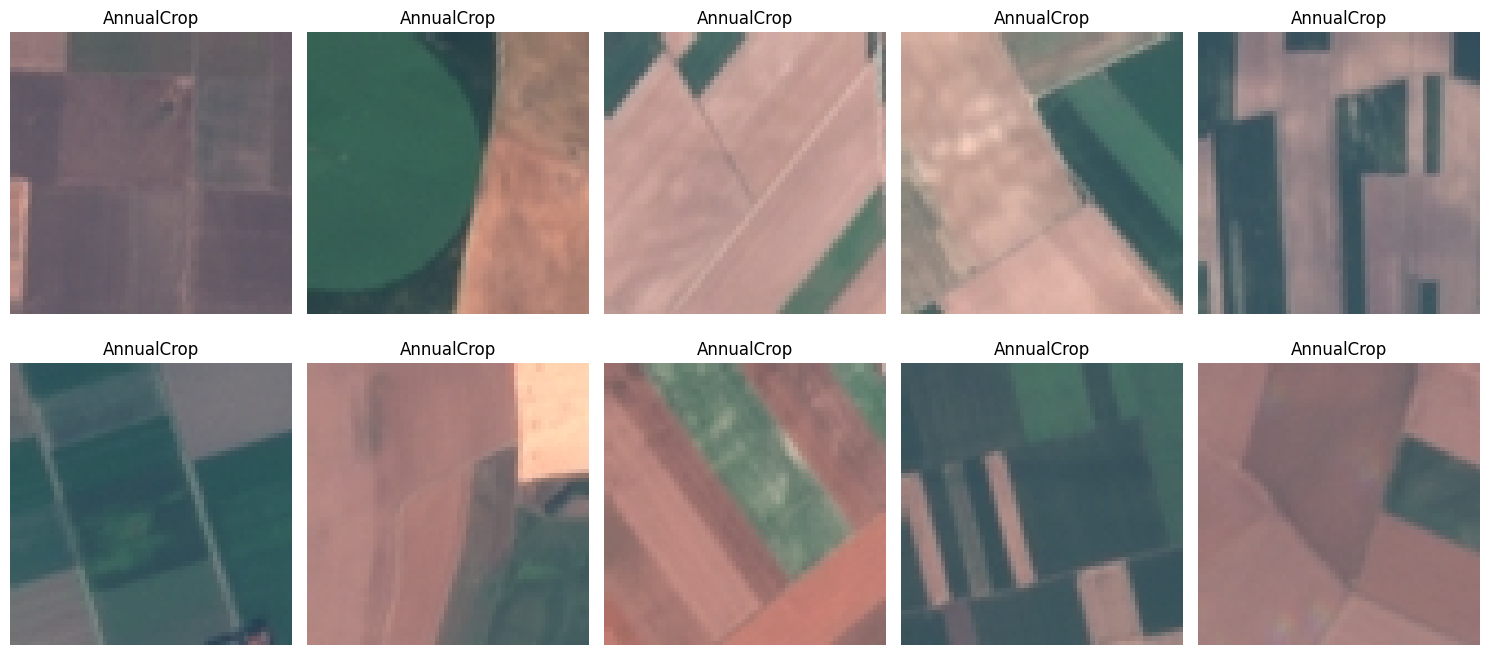

In [6]:
import matplotlib.pyplot as plt

print("Dataset size:", len(dataset))
print("Classes:", class_names)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image, label = dataset[i]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import torch
from torch.utils.data import random_split

SEED = 42
total = len(dataset)

train_size = int(0.70 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=generator
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Total:", len(train_dataset) + len(val_dataset) + len(test_dataset))

Training images: 18900
Validation images: 4050
Testing images: 4050
Total: 27000


Dataset Loaders

In [8]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 296
Validation batches: 64
Testing batches: 64


Check one batch

In [9]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Device:", device)

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])
Device: cpu


Bulid CNN Model

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class EuroSAT_CNN(nn.Module):
    def __init__(self, num_classes):
        super(EuroSAT_CNN, self).__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = EuroSAT_CNN(num_classes).to(device)

print(model)
print("Model created successfully!")

EuroSAT_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Model created successfully!


Config Training

In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 10

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Epochs:", EPOCHS)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Epochs: 10


Train Model

In [12]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):
    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # Validation
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Train Acc: {epoch_train_acc:.4f}, "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Acc: {epoch_val_acc:.4f}"
    )

Epoch [1/10] Train Loss: 1.3326, Train Acc: 0.4903, Val Loss: 1.0248, Val Acc: 0.6136
Epoch [2/10] Train Loss: 0.8833, Train Acc: 0.6868, Val Loss: 1.1099, Val Acc: 0.6017
Epoch [3/10] Train Loss: 0.7390, Train Acc: 0.7367, Val Loss: 0.6400, Val Acc: 0.7699
Epoch [4/10] Train Loss: 0.6633, Train Acc: 0.7689, Val Loss: 0.6490, Val Acc: 0.7704
Epoch [5/10] Train Loss: 0.6076, Train Acc: 0.7843, Val Loss: 0.5937, Val Acc: 0.7805
Epoch [6/10] Train Loss: 0.5497, Train Acc: 0.8081, Val Loss: 0.5014, Val Acc: 0.8284
Epoch [7/10] Train Loss: 0.5050, Train Acc: 0.8210, Val Loss: 0.4675, Val Acc: 0.8257
Epoch [8/10] Train Loss: 0.4825, Train Acc: 0.8323, Val Loss: 0.5796, Val Acc: 0.7956
Epoch [9/10] Train Loss: 0.4266, Train Acc: 0.8497, Val Loss: 0.6034, Val Acc: 0.7953
Epoch [10/10] Train Loss: 0.3899, Train Acc: 0.8623, Val Loss: 0.4565, Val Acc: 0.8388


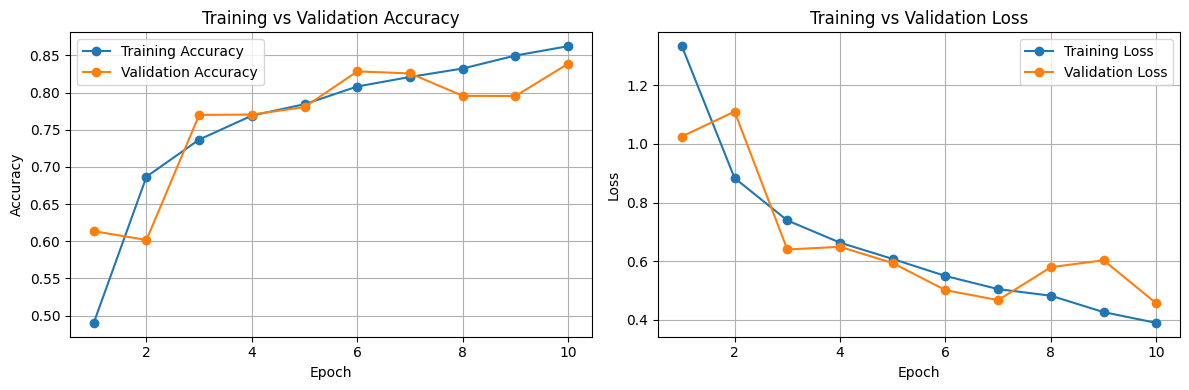

In [13]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Evaluate Model

TEST CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.80      0.92      0.85       472
              Forest       0.95      0.93      0.94       442
HerbaceousVegetation       0.83      0.75      0.79       458
             Highway       0.72      0.69      0.70       391
          Industrial       0.90      0.96      0.93       378
             Pasture       0.87      0.84      0.85       299
       PermanentCrop       0.73      0.76      0.75       379
         Residential       0.98      0.80      0.88       450
               River       0.78      0.83      0.80       375
             SeaLake       0.91      0.96      0.93       406

            accuracy                           0.85      4050
           macro avg       0.85      0.84      0.84      4050
        weighted avg       0.85      0.85      0.84      4050



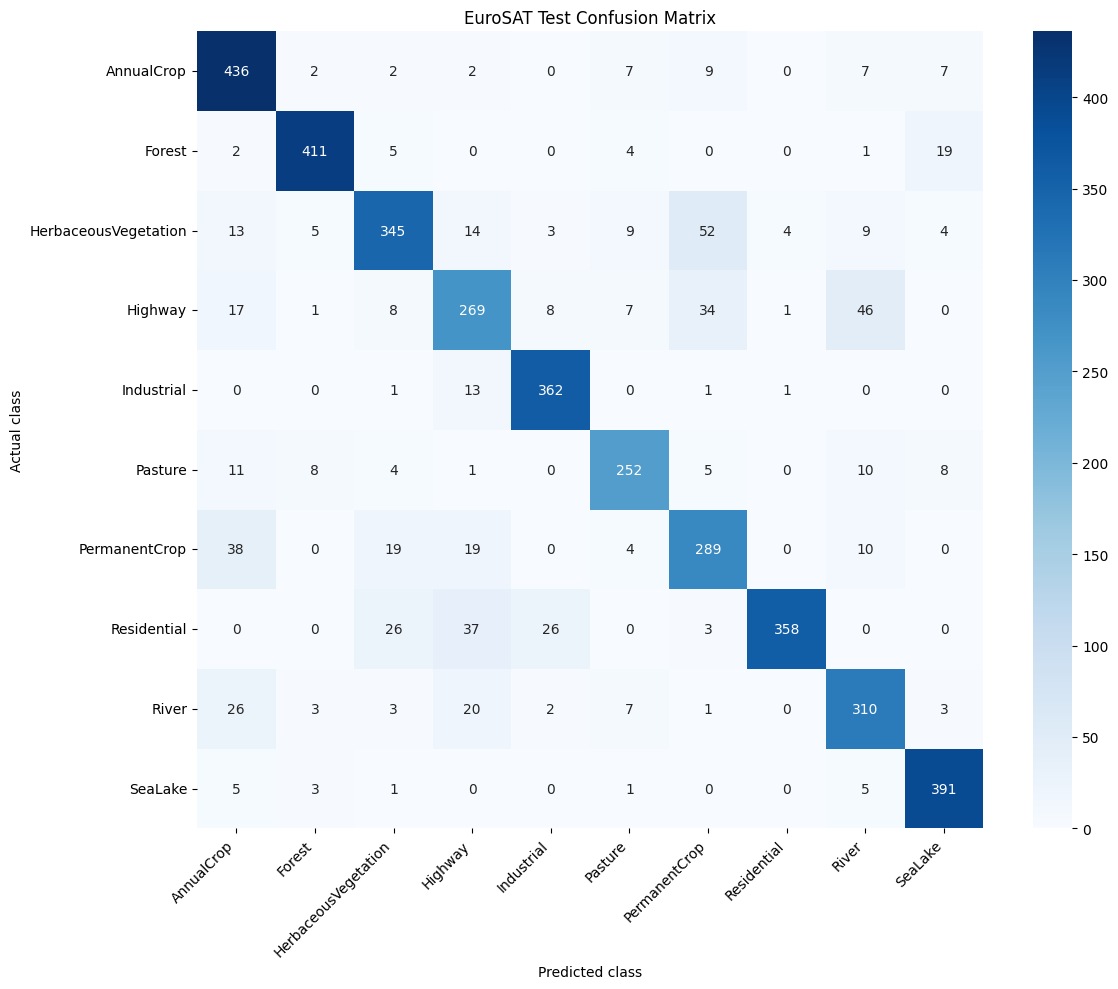

Test accuracy: 0.8451851851851852


In [14]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("TEST CLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("EuroSAT Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Test accuracy:", np.mean(np.array(all_preds) == np.array(all_labels)))

Display Misclassified images

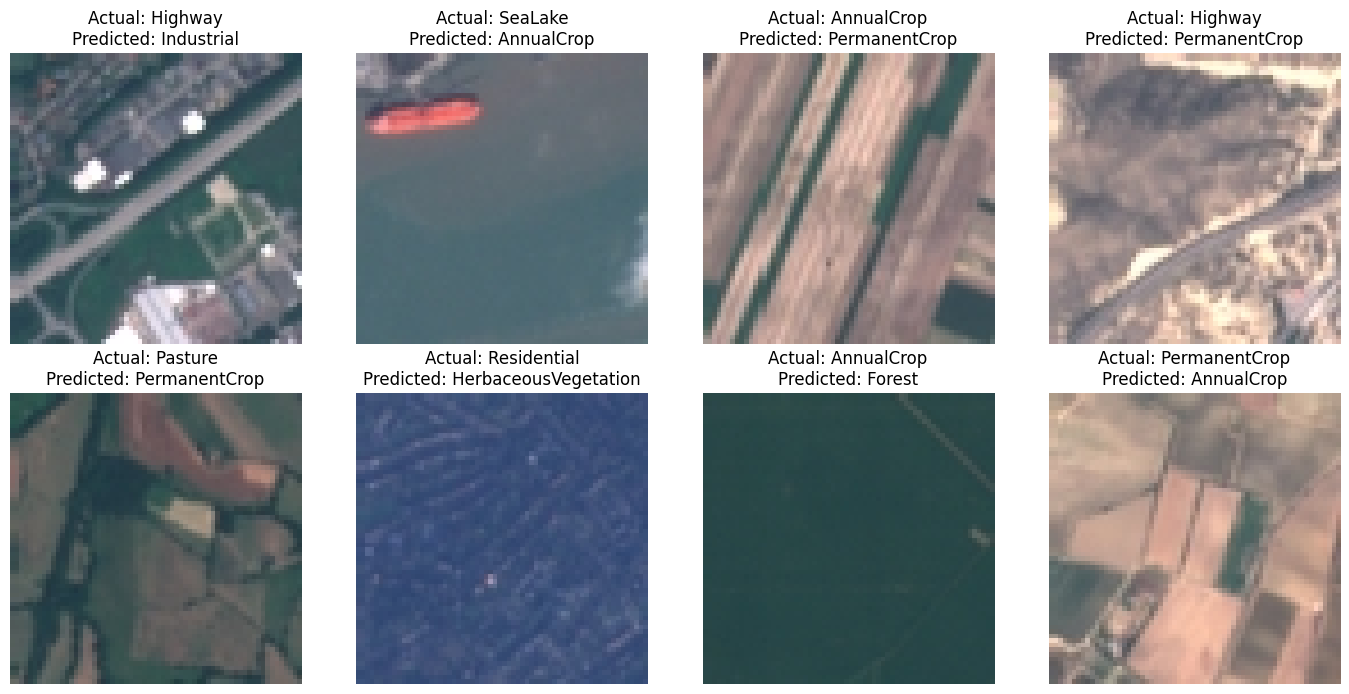

Misclassified images displayed: 8


In [15]:
import matplotlib.pyplot as plt
import torch

model.eval()
wrong_images = []
wrong_true = []
wrong_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        wrong_indices = (predictions != labels).nonzero().flatten()

        for idx in wrong_indices:
            wrong_images.append(images[idx])
            wrong_true.append(labels[idx].item())
            wrong_pred.append(predictions[idx].item())

            if len(wrong_images) >= 8:
                break

        if len(wrong_images) >= 8:
            break

if len(wrong_images) == 0:
    print("No misclassified images found in this test pass.")
else:
    count = min(8, len(wrong_images))
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for i, ax in enumerate(axes.flat):
        if i >= count:
            ax.axis("off")
            continue

        ax.imshow(wrong_images[i].permute(1, 2, 0))
        ax.set_title(
            f"Actual: {class_names[wrong_true[i]]}\n"
            f"Predicted: {class_names[wrong_pred[i]]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Misclassified images displayed:", count)

Save model

In [16]:
import torch

model_path = "/content/PS26_EuroSAT_CNN.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes
}, model_path)

print("Model saved to:", model_path)

Model saved to: /content/PS26_EuroSAT_CNN.pth


Download model

In [17]:
from google.colab import files

files.download("/content/PS26_EuroSAT_CNN.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Save Results

In [18]:
import json
import numpy as np

results = {
    "class_names": class_names,
    "epochs_completed": len(train_losses),
    "training_accuracy": train_accuracies,
    "validation_accuracy": val_accuracies,
    "training_loss": train_losses,
    "validation_loss": val_losses,
    "test_accuracy": float(
        np.mean(np.array(all_preds) == np.array(all_labels))
    )
}

with open("/content/PS26_results.json", "w") as f:
    json.dump(results, f, indent=4)

np.savez(
    "/content/PS26_test_predictions.npz",
    predictions=np.array(all_preds),
    labels=np.array(all_labels)
)

print("Training history and test results saved successfully!")

Training history and test results saved successfully!


Download

In [19]:
from google.colab import files

files.download("/content/PS26_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>